# Multiclass Classificatoin

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, f1_score

from mpl_toolkits.mplot3d import Axes3D
from sklearn.linear_model import LogisticRegression

# Parameters

In [2]:
inpDir = '../input'
outDir = '../output'

RANDOM_STATE = 24 # REMEBER : TO REMOVE AT THE TIME OF PROMOTION TO PRODUCTION
# np.random.seed(RANDOM_STATE)
rng = np.random.default_rng(seed = RANDOM_STATE)

NOISE = 0.2
EPOCHS = 20001
ALPHA = 0.1 #lr
N_SAMPLES = 1000 #no of sample to create 
TEST_SIZE = 0.2


params = { 'legend.fontsize': 'medium',
           'figure.figsize':(15,6),
           'axes.labelsize':'medium',
           'axes.titlesize':'medium',
           'xtick.labelsize': 'medium',
           'ytick.labelsize': 'medium'
}

plt.rcParams.update(params)
CMAP = plt.cm.coolwarm
plt.style.use('seaborn-v0_8-darkgrid')

# Helper Function

In [3]:
def plot_decision_boundary(model : dict,
                           X_tr : np.ndarray,
                           y_tr : np.ndarray,
                           X_ts : np.ndarray,
                           y_ts : np.ndarray):

    fig, ax = plt.subplots()
    dm = 0.01
    margin = 10*dm
    
    xMin = min(X_tr[:,0].min() - margin, X_ts[:,0].min() - margin)
    xMax = max(X_tr[:,0].max() + margin, X_ts[:,0].max() + margin)
    yMin = min(X_tr[:, 1].min() - margin, X_ts[:, 1].min() - margin)
    yMax = max(X_tr[:, 1].max() + margin, X_ts[:, 1].max() + margin)
    
    xx, yy = np.meshgrid(np.arange(xMin, xMax, dm),
                        np.arange(yMin, yMax, dm))

    XX = np.c_[xx.ravel(), yy.ravel()]

    Z = fn_predict(model, XX).reshape(xx.shape)
    
    ax.contourf(xx, yy, Z, cmap=plt.cm.Paired, alpha=0.6)
    
    ax.scatter(X_tr[:,0], 
               X_tr[:,1], 
               c = y_tr.argmax(axis=1), 
               s = 30, 
               edgecolors='k',
               cmap = CMAP)
    
    ax.scatter(X_ts[:,0], 
               X_ts[:,1], 
               c = y_ts.argmax(axis=1), 
               s = 30, 
               marker = "*",
               edgecolors='k',
               cmap = plt.cm.seismic)
    
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.set_title("Decision Boundary")
    ax.legend()

# Load Dataset

In [4]:
dir(datasets)

['__all__',
 '__builtins__',
 '__cached__',
 '__doc__',
 '__file__',
 '__getattr__',
 '__loader__',
 '__name__',
 '__package__',
 '__path__',
 '__spec__',
 '_arff_parser',
 '_base',
 '_california_housing',
 '_covtype',
 '_kddcup99',
 '_lfw',
 '_olivetti_faces',
 '_openml',
 '_rcv1',
 '_samples_generator',
 '_species_distributions',
 '_svmlight_format_fast',
 '_svmlight_format_io',
 '_twenty_newsgroups',
 'clear_data_home',
 'dump_svmlight_file',
 'fetch_20newsgroups',
 'fetch_20newsgroups_vectorized',
 'fetch_california_housing',
 'fetch_covtype',
 'fetch_file',
 'fetch_kddcup99',
 'fetch_lfw_pairs',
 'fetch_lfw_people',
 'fetch_olivetti_faces',
 'fetch_openml',
 'fetch_rcv1',
 'fetch_species_distributions',
 'get_data_home',
 'load_breast_cancer',
 'load_diabetes',
 'load_digits',
 'load_files',
 'load_iris',
 'load_linnerud',
 'load_sample_image',
 'load_sample_images',
 'load_svmlight_file',
 'load_svmlight_files',
 'load_wine',
 'make_biclusters',
 'make_blobs',
 'make_checkerboard

In [5]:
X, y = datasets.make_moons(n_samples=N_SAMPLES,
                           shuffle=True,
                           noise=NOISE,
                           random_state=RANDOM_STATE)
X[:5], y[:5]

(array([[ 0.90633951,  0.90267624],
        [-1.11536828,  0.75579289],
        [ 1.88769158,  0.4175967 ],
        [-0.93345034, -0.02299851],
        [-0.96872877,  0.06396285]]),
 array([0, 0, 1, 0, 0]))

In [6]:
y = pd.get_dummies(y).to_numpy()
y.shape

(1000, 2)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                                    test_size=TEST_SIZE, 
                                                    random_state=RANDOM_STATE, 
                                                    stratify=y)

In [8]:
# df = pd.DataFrame(data=X, columns=['A', 'B'])  # Convert features to dataframe

# # Assign each class column separately to the dataframe
# df['target_0'] = y[:, 0]
# df['target_1'] = y[:, 1]

# df.head()

In [9]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(800, 2) (200, 2) (800, 2) (200, 2)


# Different Plots

In [10]:
# plt.scatter(X[:,0],X[:,1], s=40, marker="*", c='target', cmap='coolwarm')
# plt.show()

# Sigmoid Function

In [11]:
def fn_softmax(z):
    z_shifted = z - np.max(z, axis=1, keepdims=True)
    exp_sc = np.exp(z_shifted)
    return exp_sc / np.sum(exp_sc, axis=1, keepdims=True)

In [12]:
fn_softmax(np.asarray([[8,5,0],[-10,0,+10]]))

array([[9.52269826e-01, 4.74107229e-02, 3.19450938e-04],
       [2.06106005e-09, 4.53978686e-05, 9.99954600e-01]])

# Tanh Activation Function

In [13]:
def fn_activ(z: np.ndarray) -> np.ndarray:
    return np.tanh(z)

def fn_activ_prime(z: np.ndarray) -> np.ndarray:
    return 1.0 - np.tanh(z)**2

In [14]:
fn_activ(np.asarray([[-1,0,-1],[-np.inf,0,np.inf]]))

array([[-0.76159416,  0.        , -0.76159416],
       [-1.        ,  0.        ,  1.        ]])

In [15]:
def fn_predict(model:dict, X_p:np.ndarray):
    '''
    Model : Dict Containing weights and bias
    X : Input Features
    '''
    W1, W2, W3, W4, W5 = model['W1'], model['W2'], model['W3'], model['W4'], model['W5']
    b1, b2, b3, b4, b5 = model['b1'], model['b2'], model['b3'], model['b4'], model['b5']

    # Forward propogation

    # Layer 1
    z1 = X_p.dot(W1) + b1 # Aggregation
    a1 = fn_activ(z1) # Activation

    # Layer 2
    z2 = a1.dot(W2) + b2 # Aggregation
    a2 = fn_activ(z2) #Activation

    # Layer 2
    z3 = a2.dot(W3) + b3 # Aggregation
    a3 = fn_activ(z3) #Activation

    # Layer 2
    z4 = a3.dot(W4) + b4 # Aggregation
    a4 = fn_activ(z4) #Activation

    # Layer 2
    z5 = a4.dot(W5) + b5 # Aggregation
    a5 = fn_softmax(z5) #Activation
    
    return np.argmax(a5, axis=1) # pick with highest proba

In [16]:
def fn_calculate_loss(model: dict,  X_l:  np.ndarray, y_l: np.ndarray):
    '''
    Model : Dict Containing weights and bias
    X : Input Features
    y_l : target
    '''
    m = X_l.shape[0]
    W1, W2, W3, W4, W5 = model['W1'], model['W2'], model['W3'], model['W4'], model['W5']
    b1, b2, b3, b4, b5 = model['b1'], model['b2'], model['b3'], model['b4'], model['b5']

    # Forward propogation

    # Layer 1
    z1 = X_l.dot(W1) + b1 # Aggregation
    a1 = fn_activ(z1) # Activation

    # Layer 2
    z2 = a1.dot(W2) + b2 # Aggregation
    a2 = fn_activ(z2) #Activation

    # Layer 2
    z3 = a2.dot(W3) + b3 # Aggregation
    a3 = fn_activ(z3) #Activation

    # Layer 2
    z4 = a3.dot(W4) + b4 # Aggregation
    a4 = fn_activ(z4) #Activation

    # Layer 2
    z5 = a4.dot(W5) + b5 # Aggregation
    a5 = fn_softmax(z5) #Activation

    eps = 1e-7
    a5 = np.clip(a5, eps, 1- eps)
    
    data_loss = -(y_l * np.log(a5)).sum()

    return data_loss / m

In [17]:
# weights = np.array([0.1,2.0,1.0])

# display(df.iloc[0])
# fn_predict(df.iloc[0].values, weights)
# single_sample = df.iloc[0][['A', 'B']].values.reshape(1, -1)
# prediction = fn_predict(model, single_sample)
# print("Prediction:", prediction)

In [18]:
def fn_build_model(param : dict, 
                   X: np.ndarray,
                   y: np.ndarray,
                   alpha: np.float64=ALPHA,
                   n_epochs: np.int64=EPOCHS) -> dict:
    '''
    nn_hdim :number of hidden units 
    X: features
    y: labels/target
    alpha: learning rate
    n_epochs: number of passes through complete data for gradient descent
    '''
    m, nn_input_dim = X.shape
    nn_output_dim = y.shape[1]

    W1 = rng.random((param['nn_hdim'][0], param['nn_hdim'][1]), dtype=np.float32) / np.sqrt(param['nn_hdim'][0])
    W2 = rng.random((param['nn_hdim'][1], param['nn_hdim'][2]), dtype=np.float32) / np.sqrt(param['nn_hdim'][1])
    W3 = rng.random((param['nn_hdim'][2], param['nn_hdim'][3]), dtype=np.float32) / np.sqrt(param['nn_hdim'][2])
    W4 = rng.random((param['nn_hdim'][3], param['nn_hdim'][4]), dtype=np.float32) / np.sqrt(param['nn_hdim'][3])
    W5 = rng.random((param['nn_hdim'][4], nn_output_dim), dtype=np.float32) / np.sqrt(param['nn_hdim'][4])
    
   
    b1 = np.zeros((1, param['nn_hdim'][1]), dtype=np.float32)
    b2 = np.zeros((1, param['nn_hdim'][2]), dtype=np.float32)
    b3 = np.zeros((1, param['nn_hdim'][3]), dtype=np.float32)
    b4 = np.zeros((1, param['nn_hdim'][4]), dtype=np.float32)
    b5 = np.zeros((1, nn_output_dim), dtype=np.float32)
    
    curr_loss = 0
    loss, epoch = [],[]

    for i in range(n_epochs):
        # Forward Propogation
        
        # Layer 1
        z1 = X.dot(W1) + b1 # Aggregation
        a1 = fn_activ(z1) # Activation
    
        # Layer 2
        z2 = a1.dot(W2) + b2 # Aggregation
        a2 = fn_activ(z2) #Activation
    
        # Layer 3
        z3 = a2.dot(W3) + b3 # Aggregation
        a3 = fn_activ(z3) #Activation
    
        # Layer 4
        z4 = a3.dot(W4) + b4 # Aggregation
        a4 = fn_activ(z4) #Activation
    
        # Layer 5
        z5 = a4.dot(W5) + b5 # Aggregation
        a5 = fn_softmax(z5) #Activation

        # Back Propogation
        
        # Layer5
        dz5 = a5 - y
        dW5 = (a4.T).dot(dz5)
        assert (W5.shape == dW5.shape), f'Shape - W5:{W5.shape} | dW5:{dW5.shape}'
        db5 = np.sum(dz5, axis=0, keepdims=True)
        assert (b5.shape == db5.shape), f'Shape - b5:{b5.shape} | db5:{db5.shape}'
        da4 = dz5.dot(W5.T)
        assert (a4.shape == da4.shape), f'Shape - a4:{a4.shape} | da4:{da4.shape}'

        #Layer 4  
        dz4 = da4* fn_activ_prime(z4)
        dW4 = (a3.T).dot(dz4)
        assert (W4.shape == dW4.shape), f'Shape- W4:{W4.shape} | dW4: {dW4.shape}'
        db4 = np.sum(dz4, axis=0, keepdims=True)
        assert (b4.shape == db4.shape), f'Shape- b4:{b4.shape} | db4: {db4.shape}'
        da3 = dz4.dot(W4.T)
        assert (a3.shape == da3.shape), f'Shape- a3:{a3.shape} | da3:{da3.shape}'
    
        #Layer 3 
        dz3 = da3* fn_activ_prime(z3)
        dW3 = (a2.T).dot(dz3)
        assert (W3.shape == dW3.shape), f'Shape- W3:{W3.shape} | dW3: {dW3.shape}'
        db3 = np.sum(dz3, axis=0, keepdims=True)
        assert (b3.shape == db3.shape), f'Shape- b3:{b3.shape} | db3: {db3.shape}'
        da2 = dz3.dot(W3.T)
        assert (a2.shape == da2.shape), f'Shape- a2:{a2.shape} | da2:{da2.shape}'
    
        #Layer 2  
        dz2 = da2* fn_activ_prime(z2)
        dW2 = (a1.T).dot(dz2)
        assert (W2.shape == dW2.shape), f'Shape- W2:{W2.shape} | dW2: {dW2.shape}'
        db2 = np.sum(dz2, axis=0, keepdims=True)
        assert (b2.shape == db2.shape), f'Shape- b2:{b2.shape} | db2: {db2.shape}'
        da1 = dz2.dot(W2.T)
        assert (a1.shape == da1.shape), f'Shape- a1:{a1.shape} | da1:{da1.shape}'
    
        #Layer 1
        dz1 = da1*fn_activ_prime(z1)
        dW1 = (X.T).dot(dz1)
        assert (W1.shape == dW1.shape), f'Shape- W1:{W1.shape} | dW1:{dW1.shape}'
        db1 = np.sum(dz1 , axis = 0, keepdims=True)
        assert (b1.shape == db1.shape), f'Shape - b1:{b1.shape} | db1:{db1.shape}'
        
        W1 = W1 - alpha * dW1 / m
        W2 = W2 - alpha * dW2 / m
        W3 = W3 - alpha * dW3 / m
        W4 = W4 - alpha * dW4 / m
        W5 = W5 - alpha * dW5 / m
        

        
        b1 = b1 - alpha * db1 / m
        b2 = b2 - alpha * db2 / m
        b3 = b3 - alpha * db3 / m
        b4 = b4 - alpha * db4 / m
        b5 = b5 - alpha * db5/ m
        

        model = {"W1": W1, "W2": W2, "W3": W3, "W4": W4, "W5": W5, 
                 "b1": b1, "b2": b2, "b3": b3, "b4": b4, "b5": b5}

        if i % 100 == 0:
            curr_loss = fn_calculate_loss(model=model, X_l = X, y_l=y)
            loss.append(curr_loss)
            epoch.append(i)
            print(f"Epoch {i:3d}: Loss = {curr_loss:.4f}")
            
    loss_hist["epoch"] = epoch
    loss_hist["loss"] = loss
    return model

In [19]:
loss_hist = {}
layer_param = {}
layer_param['nn_hdim'] = [X_train.shape[1],200,200,160,120]
model = fn_build_model(layer_param, X_train, y_train)

Epoch   0: Loss = 2.3851
Epoch 100: Loss = 2.8890
Epoch 200: Loss = 3.4915
Epoch 300: Loss = 3.4672
Epoch 400: Loss = 3.3712
Epoch 500: Loss = 3.3555
Epoch 600: Loss = 3.3548
Epoch 700: Loss = 3.3547
Epoch 800: Loss = 3.3547
Epoch 900: Loss = 3.3546
Epoch 1000: Loss = 3.3546
Epoch 1100: Loss = 3.3545
Epoch 1200: Loss = 3.3544
Epoch 1300: Loss = 3.3544
Epoch 1400: Loss = 3.3543
Epoch 1500: Loss = 3.3542
Epoch 1600: Loss = 3.3541
Epoch 1700: Loss = 3.3541
Epoch 1800: Loss = 3.3540
Epoch 1900: Loss = 3.3539
Epoch 2000: Loss = 3.3538
Epoch 2100: Loss = 3.3537
Epoch 2200: Loss = 3.3536
Epoch 2300: Loss = 3.3535
Epoch 2400: Loss = 3.3534
Epoch 2500: Loss = 3.3533
Epoch 2600: Loss = 3.3531
Epoch 2700: Loss = 3.3530
Epoch 2800: Loss = 3.3528
Epoch 2900: Loss = 3.3526
Epoch 3000: Loss = 3.3523
Epoch 3100: Loss = 3.3519
Epoch 3200: Loss = 3.3514
Epoch 3300: Loss = 3.3506
Epoch 3400: Loss = 3.3491
Epoch 3500: Loss = 3.3471
Epoch 3600: Loss = 3.3443
Epoch 3700: Loss = 3.3100
Epoch 3800: Loss = 3.2

<Axes: xlabel='epoch'>

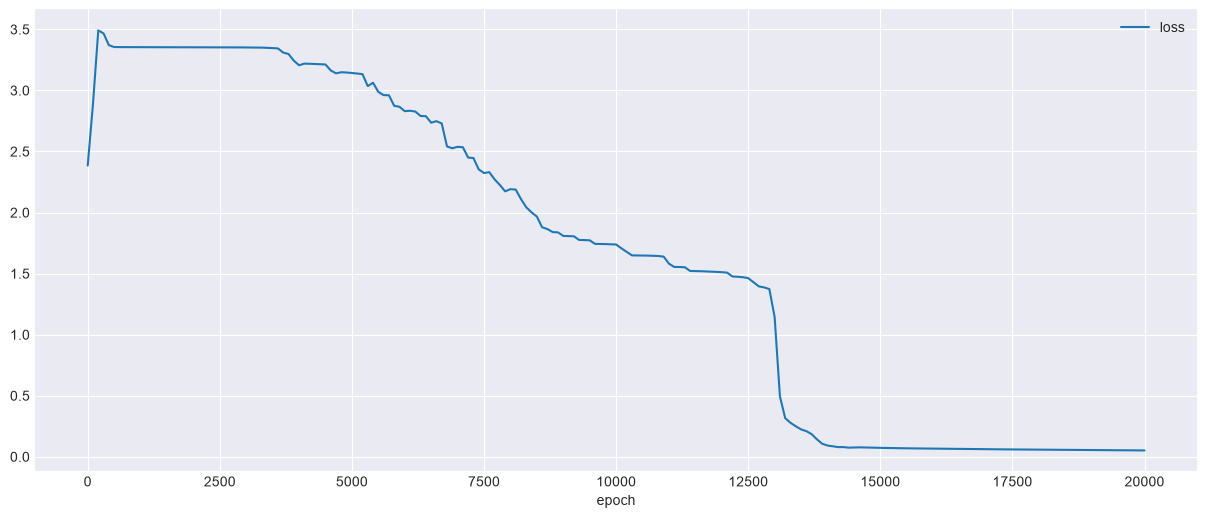

In [20]:
loss_df = pd.DataFrame(loss_hist)
fig, ax = plt.subplots()
loss_df.plot(x = 'epoch', y = 'loss', ax = ax)

In [21]:
y_pred_train = fn_predict(model=model, X_p=X_train)

# Convert one-hot encoded y_train to 1D integer labels using np.argmax
y_train_labels = np.argmax(y_train, axis=1)

f1_Score = f1_score(y_true=y_train_labels, y_pred=y_pred_train, average='weighted')
train_acc = accuracy_score(y_train_labels, y_pred_train)

print(f"Train F1-Score: {f1_Score:.4f}")
print(f"Train Accuracy: {train_acc:.4f}")

Train F1-Score: 0.9762
Train Accuracy: 0.9762


In [22]:
y_pred_test = fn_predict(model=model, X_p=X_test)

# Convert one-hot encoded y_test to 1D integer labels using np.argmax
y_test_labels = np.argmax(y_test, axis=1)

test_f1 = f1_score(y_true=y_test_labels, y_pred=y_pred_test, average='weighted')
test_acc = accuracy_score(y_test_labels, y_pred_test)

print(f"Test F1-Score: {test_f1:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Test F1-Score: 0.9750
Test Accuracy: 0.9750


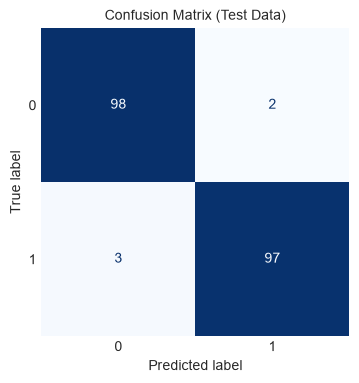

In [23]:
cm = confusion_matrix(y_test_labels, y_pred_test)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])

fig, ax = plt.subplots(figsize=(4, 4))
disp.plot(ax=ax, cmap=plt.cm.Blues, colorbar=False)
plt.title("Confusion Matrix (Test Data)")
plt.grid()
plt.show()

C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Temp\ipykernel_7148\2916271246.py:43: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


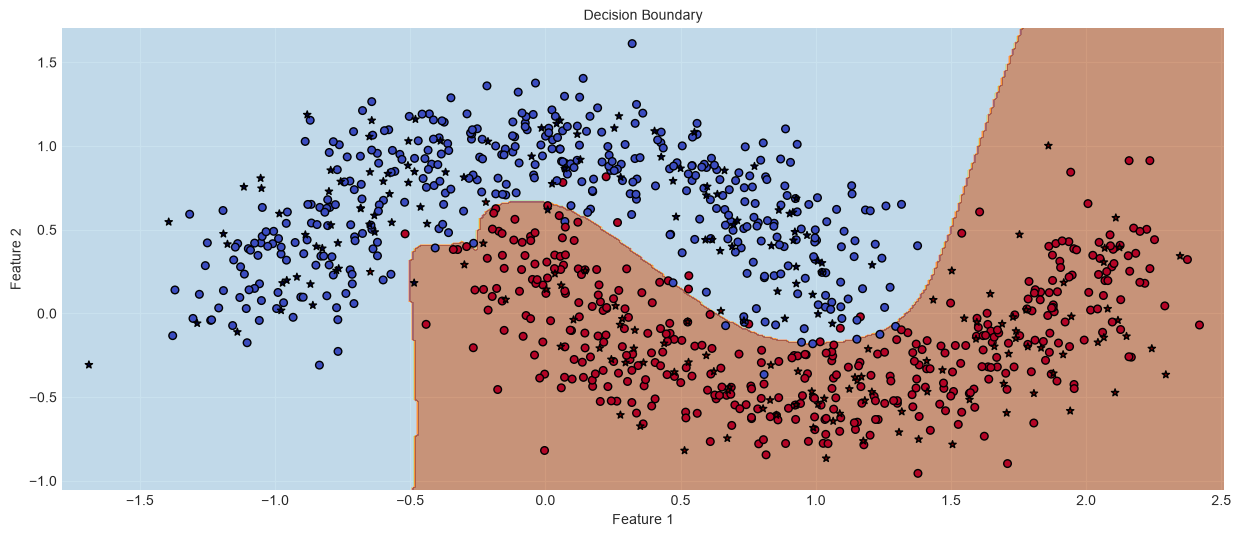

In [24]:
plot_decision_boundary(model, X_train, y_train, X_test, y_test)